# Building Modular Agentic Workflows with LangGraph Subgraphs

## Tutorial Overview

In this tutorial, you'll learn how to build a **Fact-Checking News Article Assistant** using **LangGraph subgraphs**. This is an advanced architectural pattern that allows you to:

- Break complex workflows into modular, reusable components
- Create subgraphs that can be called multiple times with different inputs
- Build sophisticated multi-step verification systems
- Maintain clean separation of concerns in your agentic architecture

## Learning Objectives

By the end of this tutorial, you will be able to:

1. Design and implement modular workflows using LangGraph subgraphs
2. Create reusable subgraphs that can be invoked multiple times
3. Build a complete fact-checking system with claim extraction and verification
4. Integrate external tools (Tavily) for real-time information gathering
5. Orchestrate complex parent-child graph relationships
6. Visualize multi-level graph architectures

## What You'll Build

We'll build a **Fact-Checking News Article Assistant** with the following architecture:

```
Main Workflow:
  Article Input → Extract Claims → Verify Each Claim → Generate Report
                        ↓                  ↓
                  Claim Extraction    Verification
                    Subgraph          Subgraph (reusable)
                                           ↓
                                  Source Quality
                                    Subgraph
```

### Workflow Components:

1. **Claim Extraction Subgraph**: Parses article → Identifies factual claims → Ranks by verifiability
2. **Verification Subgraph** (reusable): Searches sources → Compares information → Rates confidence
3. **Source Quality Subgraph**: Analyzes credibility → Checks freshness → Cross-references
4. **Main Workflow**: Orchestrates the entire process and generates final report

## Prerequisites

- Understanding of LangGraph basics (nodes, edges, state)
- Familiarity with LLM API calls
- API keys for:
  - OpenAI (or another LLM provider)
  - Tavily (for web search)

## Part 1: Environment Setup

Let's install required packages and configure our environment.

In [1]:
# Install required packages
# Uncomment the following line if you need to install the packages
# !pip install langgraph langchain langchain-openai python-dotenv tavily-python

In [2]:
# Load environment variables
from dotenv import load_dotenv
import os

# Load API keys from .env file
load_dotenv()

# Verify that keys are loaded
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found in environment"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found in environment"

print("Environment variables loaded successfully!")

Environment variables loaded successfully!


## Part 2: Import Dependencies

In [3]:
from typing import TypedDict, List, Dict, Any
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field
from tavily import TavilyClient
import json

print("All imports successful!")

All imports successful!


## Part 3: Initialize Tools and LLM

We'll set up our LLM and Tavily search client for web searches.

In [4]:
# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Initialize Tavily client for web search
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

# Create a search tool function
def internet_search(query: str, max_results: int = 5) -> dict:
    """
    Search the web for information using Tavily.
    
    Args:
        query: The search query string
        max_results: Maximum number of results to return (default: 5)
    
    Returns:
        Dictionary containing search results with titles, URLs, and content
    """
    try:
        results = tavily_client.search(query, max_results=max_results)
        return results
    except Exception as e:
        return {"error": f"Search failed: {str(e)}"}

print("Tavily search tool configured successfully!")
print("LLM and tools initialized!")

Tavily search tool configured successfully!
LLM and tools initialized!


## Part 4: Define State Schemas

We'll define separate state schemas for:
1. Main workflow state
2. Claim extraction subgraph state
3. Verification subgraph state
4. Source quality subgraph state

This demonstrates the power of subgraphs: each can have its own state schema that doesn't pollute the parent state.

In [5]:
# Pydantic models for structured outputs

class Claim(BaseModel):
    """A single factual claim extracted from an article."""
    claim_text: str = Field(description="The specific factual claim")
    verifiability_score: float = Field(description="Score 0-1 indicating how verifiable this claim is")
    context: str = Field(description="Relevant context from the article")

class ClaimList(BaseModel):
    """List of claims extracted from an article."""
    claims: List[Claim] = Field(description="List of extracted claims")

class SourceQuality(BaseModel):
    """Quality assessment of a source."""
    credibility_score: float = Field(description="Score 0-1 for source credibility")
    freshness_score: float = Field(description="Score 0-1 for information freshness")
    relevance_score: float = Field(description="Score 0-1 for relevance to claim")
    reasoning: str = Field(description="Explanation of the scores")

class VerificationResult(BaseModel):
    """Result of verifying a single claim."""
    claim: str = Field(description="The claim that was verified")
    verdict: str = Field(description="TRUE, FALSE, PARTIALLY_TRUE, or UNVERIFIABLE")
    confidence: float = Field(description="Confidence score 0-1")
    evidence: str = Field(description="Supporting evidence and reasoning")
    sources: List[str] = Field(description="URLs of sources used")

# State schemas for different graph levels

class MainWorkflowState(TypedDict):
    """State for the main fact-checking workflow."""
    article: str
    claims: List[Dict[str, Any]]
    verification_results: List[Dict[str, Any]]
    final_report: str

class ClaimExtractionState(TypedDict):
    """State for claim extraction subgraph."""
    article: str
    raw_claims: str
    ranked_claims: List[Dict[str, Any]]

class VerificationState(TypedDict):
    """State for verification subgraph."""
    claim: str
    search_results: List[Dict[str, Any]]
    source_quality_assessments: List[Dict[str, Any]]
    verification_result: Dict[str, Any]

class SourceQualityState(TypedDict):
    """State for source quality subgraph."""
    source_url: str
    source_content: str
    claim: str
    quality_assessment: Dict[str, Any]

print("State schemas defined!")
print("\nWe have 4 separate state schemas:")
print("  1. MainWorkflowState - orchestrates the entire process")
print("  2. ClaimExtractionState - handles claim extraction")
print("  3. VerificationState - verifies individual claims")
print("  4. SourceQualityState - assesses source quality")

State schemas defined!

We have 4 separate state schemas:
  1. MainWorkflowState - orchestrates the entire process
  2. ClaimExtractionState - handles claim extraction
  3. VerificationState - verifies individual claims
  4. SourceQualityState - assesses source quality


## Part 5: Build the Claim Extraction Subgraph

This subgraph will:
1. Parse the article and identify factual claims
2. Rank claims by verifiability
3. Return a structured list of claims

This is our first example of a subgraph with its own internal workflow.

In [6]:
# Node 1: Extract raw claims from article
def extract_claims_node(state: ClaimExtractionState) -> ClaimExtractionState:
    """
    Analyzes the article and extracts factual claims using structured output.
    """
    article = state["article"]
    
    print("Extracting claims from article...")
    
    system_prompt = """You are a fact-checking expert that extracts verifiable claims from news articles.
    
Analyze the article and identify specific factual claims that can be verified.
Focus on:
- Statistical claims (numbers, percentages, dates)
- Claims about events that happened
- Statements about people, places, or organizations
- Cause-and-effect relationships

Avoid:
- Opinions or subjective statements
- Vague or ambiguous claims
- Claims that are definitional or tautological

For each claim, assess its verifiability (0-1 score):
- 1.0: Highly verifiable (specific, concrete, with clear metrics)
- 0.5: Moderately verifiable (some specificity, but may require interpretation)
- 0.0: Not verifiable (too vague, subjective, or opinion-based)
"""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": f"Article:\n{article}"}
    ]
    
    # Use structured output
    claim_extractor = llm.with_structured_output(ClaimList)
    result = claim_extractor.invoke(messages)
    
    print(f"Extracted {len(result.claims)} claims")
    
    return {**state, "raw_claims": str(result.model_dump())}

# Node 2: Rank claims by verifiability
def rank_claims_node(state: ClaimExtractionState) -> ClaimExtractionState:
    """
    Ranks extracted claims by verifiability score.
    """
    raw_claims = eval(state["raw_claims"])  # Convert string back to dict
    claims_list = raw_claims["claims"]
    
    print("Ranking claims by verifiability...")
    
    # Sort claims by verifiability score (highest first)
    ranked = sorted(claims_list, key=lambda x: x["verifiability_score"], reverse=True)
    
    # Take top 3 most verifiable claims
    top_claims = ranked[:3]
    
    print(f"Selected top {len(top_claims)} claims for verification")
    for i, claim in enumerate(top_claims, 1):
        print(f"  {i}. [{claim['verifiability_score']:.2f}] {claim['claim_text'][:80]}...")
    
    return {**state, "ranked_claims": top_claims}

# Build the claim extraction subgraph
claim_extraction_builder = StateGraph(ClaimExtractionState)

# Add nodes
claim_extraction_builder.add_node("extract_claims", extract_claims_node)
claim_extraction_builder.add_node("rank_claims", rank_claims_node)

# Add edges
claim_extraction_builder.add_edge(START, "extract_claims")
claim_extraction_builder.add_edge("extract_claims", "rank_claims")
claim_extraction_builder.add_edge("rank_claims", END)

# Compile the subgraph
claim_extraction_subgraph = claim_extraction_builder.compile()

print("\nClaim Extraction Subgraph built!")
print("Architecture: extract_claims → rank_claims")


Claim Extraction Subgraph built!
Architecture: extract_claims → rank_claims


## Part 6: Build the Source Quality Subgraph

This subgraph assesses the quality of individual sources found during verification.
It will be used by the verification subgraph.

In [7]:
def assess_source_quality_node(state: SourceQualityState) -> SourceQualityState:
    """
    Assesses the quality of a source for fact-checking purposes.
    """
    source_url = state["source_url"]
    source_content = state["source_content"]
    claim = state["claim"]
    
    print(f"Assessing source quality: {source_url[:60]}...")
    
    system_prompt = """You are a source quality assessor for fact-checking.

Evaluate the source on three dimensions:

1. Credibility (0-1):
   - Is this from a reputable organization?
   - Does it cite sources or provide evidence?
   - Is the author identified and credible?

2. Freshness (0-1):
   - Is the information recent and up-to-date?
   - Is it relevant to the current context?

3. Relevance (0-1):
   - How directly does this source address the claim?
   - Does it provide specific evidence for or against the claim?
"""
    
    user_prompt = f"""Claim: {claim}

Source URL: {source_url}

Source Content:
{source_content[:1000]}...

Assess the quality of this source for verifying the claim."""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    
    # Use structured output
    quality_assessor = llm.with_structured_output(SourceQuality)
    result = quality_assessor.invoke(messages)
    
    print(f"  Credibility: {result.credibility_score:.2f}, Freshness: {result.freshness_score:.2f}, Relevance: {result.relevance_score:.2f}")
    
    return {**state, "quality_assessment": result.model_dump()}

# Build the source quality subgraph
source_quality_builder = StateGraph(SourceQualityState)

# Add nodes
source_quality_builder.add_node("assess_quality", assess_source_quality_node)

# Add edges
source_quality_builder.add_edge(START, "assess_quality")
source_quality_builder.add_edge("assess_quality", END)

# Compile the subgraph
source_quality_subgraph = source_quality_builder.compile()

print("\nSource Quality Subgraph built!")


Source Quality Subgraph built!


## Part 7: Build the Verification Subgraph

This is the most complex subgraph. It will:
1. Search for sources related to the claim
2. Use the source quality subgraph to assess each source
3. Compare information across sources
4. Generate a verification result with confidence score

This subgraph will be called multiple times by the main workflow - once for each claim.

In [8]:
# Node 1: Search for sources
def search_sources_node(state: VerificationState) -> VerificationState:
    """
    Searches the web for sources related to the claim.
    """
    claim = state["claim"]
    
    print(f"\nSearching for sources to verify: {claim[:80]}...")
    
    # Perform web search
    search_results = internet_search(claim, max_results=3)
    
    if "error" in search_results:
        print(f"Search error: {search_results['error']}")
        return {**state, "search_results": []}
    
    results = search_results.get("results", [])
    print(f"Found {len(results)} sources")
    
    return {**state, "search_results": results}

# Node 2: Assess source quality (calls source quality subgraph)
def assess_sources_node(state: VerificationState) -> VerificationState:
    """
    Assesses the quality of each source by invoking the source quality subgraph.
    """
    claim = state["claim"]
    search_results = state["search_results"]
    
    print("Assessing source quality for all sources...")
    
    quality_assessments = []
    
    for result in search_results:
        # Invoke the source quality subgraph for each source
        subgraph_input = {
            "source_url": result.get("url", ""),
            "source_content": result.get("content", ""),
            "claim": claim,
            "quality_assessment": {}
        }
        
        # This is where we invoke a subgraph from within another subgraph!
        subgraph_output = source_quality_subgraph.invoke(subgraph_input)
        
        quality_assessments.append({
            "url": result.get("url", ""),
            "quality": subgraph_output["quality_assessment"]
        })
    
    return {**state, "source_quality_assessments": quality_assessments}

# Node 3: Generate verification result
def generate_verdict_node(state: VerificationState) -> VerificationState:
    """
    Generates the final verification verdict based on sources and quality assessments.
    """
    claim = state["claim"]
    search_results = state["search_results"]
    quality_assessments = state["source_quality_assessments"]
    
    print("Generating verification verdict...")
    
    # Prepare context with sources and quality scores
    sources_context = ""
    for i, (result, quality) in enumerate(zip(search_results, quality_assessments), 1):
        sources_context += f"\n\nSource {i}:\n"
        sources_context += f"URL: {result.get('url', 'N/A')}\n"
        sources_context += f"Content: {result.get('content', '')[:500]}...\n"
        sources_context += f"Quality Scores - Credibility: {quality['quality']['credibility_score']:.2f}, "
        sources_context += f"Freshness: {quality['quality']['freshness_score']:.2f}, "
        sources_context += f"Relevance: {quality['quality']['relevance_score']:.2f}\n"
    
    system_prompt = """You are a fact-checking expert that verifies claims based on source evidence.

Analyze the sources and their quality scores to determine:

Verdict:
- TRUE: The claim is supported by high-quality sources
- FALSE: The claim is contradicted by high-quality sources
- PARTIALLY_TRUE: Some aspects are true, others are not
- UNVERIFIABLE: Insufficient or conflicting evidence

Confidence (0-1):
- Consider source quality scores
- Higher confidence when multiple high-quality sources agree
- Lower confidence when sources conflict or quality is poor

Provide clear evidence and reasoning.
"""
    
    user_prompt = f"""Claim to verify: {claim}

Available sources:
{sources_context}

Verify this claim and provide your verdict."""
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    
    # Use structured output
    verifier = llm.with_structured_output(VerificationResult)
    result = verifier.invoke(messages)
    
    print(f"Verdict: {result.verdict} (confidence: {result.confidence:.2f})")
    
    return {**state, "verification_result": result.model_dump()}

# Build the verification subgraph
verification_builder = StateGraph(VerificationState)

# Add nodes
verification_builder.add_node("search_sources", search_sources_node)
verification_builder.add_node("assess_sources", assess_sources_node)
verification_builder.add_node("generate_verdict", generate_verdict_node)

# Add edges
verification_builder.add_edge(START, "search_sources")
verification_builder.add_edge("search_sources", "assess_sources")
verification_builder.add_edge("assess_sources", "generate_verdict")
verification_builder.add_edge("generate_verdict", END)

# Compile the subgraph
verification_subgraph = verification_builder.compile()

print("\nVerification Subgraph built!")
print("Architecture: search_sources → assess_sources → generate_verdict")
print("Note: assess_sources internally calls the source_quality_subgraph!")


Verification Subgraph built!
Architecture: search_sources → assess_sources → generate_verdict
Note: assess_sources internally calls the source_quality_subgraph!


## Part 8: Build the Main Workflow

Now we'll create the main workflow that orchestrates everything:
1. Takes an article as input
2. Calls the claim extraction subgraph
3. Calls the verification subgraph for each claim (demonstrating reusability)
4. Generates a final fact-checking report

This demonstrates the key pattern: invoking subgraphs from parent nodes.

In [9]:
# Node 1: Extract claims (invokes claim extraction subgraph)
def extract_claims_main(state: MainWorkflowState) -> MainWorkflowState:
    """
    Extracts claims from the article by invoking the claim extraction subgraph.
    """
    article = state["article"]
    
    print("="*80)
    print("STEP 1: EXTRACTING CLAIMS")
    print("="*80)
    
    # Transform parent state to subgraph state
    subgraph_input = {
        "article": article,
        "raw_claims": "",
        "ranked_claims": []
    }
    
    # Invoke the claim extraction subgraph
    subgraph_output = claim_extraction_subgraph.invoke(subgraph_input)
    
    # Transform subgraph output back to parent state
    claims = subgraph_output["ranked_claims"]
    
    return {**state, "claims": claims}

# Node 2: Verify all claims (invokes verification subgraph multiple times)
def verify_claims_main(state: MainWorkflowState) -> MainWorkflowState:
    """
    Verifies each claim by invoking the verification subgraph.
    This demonstrates subgraph reusability - we call it multiple times.
    """
    claims = state["claims"]
    
    print("\n" + "="*80)
    print("STEP 2: VERIFYING CLAIMS")
    print("="*80)
    
    verification_results = []
    
    # Invoke the verification subgraph once for each claim
    for i, claim_obj in enumerate(claims, 1):
        print(f"\n--- Verifying Claim {i}/{len(claims)} ---")
        
        # Transform parent state to subgraph state
        subgraph_input = {
            "claim": claim_obj["claim_text"],
            "search_results": [],
            "source_quality_assessments": [],
            "verification_result": {}
        }
        
        # Invoke the verification subgraph
        subgraph_output = verification_subgraph.invoke(subgraph_input)
        
        # Collect the result
        verification_results.append(subgraph_output["verification_result"])
    
    return {**state, "verification_results": verification_results}

# Node 3: Generate final report
def generate_report_main(state: MainWorkflowState) -> MainWorkflowState:
    """
    Generates a comprehensive fact-checking report.
    """
    verification_results = state["verification_results"]
    
    print("\n" + "="*80)
    print("STEP 3: GENERATING REPORT")
    print("="*80)
    
    system_prompt = """You are a fact-checking report writer.

Create a clear, professional fact-checking report that:
- Summarizes the verification results
- Explains the evidence for each claim
- Provides an overall assessment
- Uses clear formatting with sections and bullet points
"""
    
    user_prompt = f"""Generate a fact-checking report for these verification results:

{json.dumps(verification_results, indent=2)}

Create a comprehensive report."""
    
    messages = [
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ]
    
    response = llm.invoke(messages)
    
    print("Report generated!")
    
    return {**state, "final_report": response.content}

# Build the main workflow
main_workflow_builder = StateGraph(MainWorkflowState)

# Add nodes
main_workflow_builder.add_node("extract_claims", extract_claims_main)
main_workflow_builder.add_node("verify_claims", verify_claims_main)
main_workflow_builder.add_node("generate_report", generate_report_main)

# Add edges
main_workflow_builder.add_edge(START, "extract_claims")
main_workflow_builder.add_edge("extract_claims", "verify_claims")
main_workflow_builder.add_edge("verify_claims", "generate_report")
main_workflow_builder.add_edge("generate_report", END)

# Compile the main workflow
fact_checker_app = main_workflow_builder.compile()

print("\n" + "="*80)
print("MAIN WORKFLOW BUILT SUCCESSFULLY!")
print("="*80)
print("\nArchitecture:")
print("  extract_claims → verify_claims → generate_report")
print("\nSubgraph relationships:")
print("  - extract_claims invokes: claim_extraction_subgraph")
print("  - verify_claims invokes: verification_subgraph (multiple times)")
print("  - verification_subgraph invokes: source_quality_subgraph (multiple times)")


MAIN WORKFLOW BUILT SUCCESSFULLY!

Architecture:
  extract_claims → verify_claims → generate_report

Subgraph relationships:
  - extract_claims invokes: claim_extraction_subgraph
  - verify_claims invokes: verification_subgraph (multiple times)
  - verification_subgraph invokes: source_quality_subgraph (multiple times)


## Part 9: Visualize the Complete Graph

Let's visualize the main workflow and understand the complete architecture.

Main Workflow Visualization:


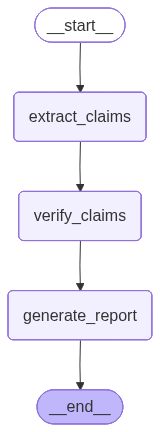

In [10]:
# Visualize the main workflow
try:
    from IPython.display import Image, display
    
    print("Main Workflow Visualization:")
    display(Image(fact_checker_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Visualization not available: {e}")
    print("\nASCII representation:")
    print(fact_checker_app.get_graph().draw_ascii())


CLAIM EXTRACTION SUBGRAPH


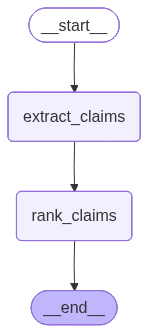


VERIFICATION SUBGRAPH


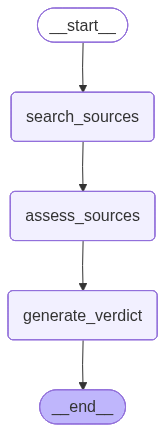


SOURCE QUALITY SUBGRAPH


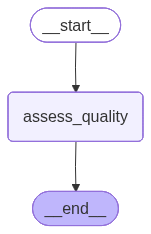

In [11]:
# Visualize the subgraphs
print("\n" + "="*80)
print("CLAIM EXTRACTION SUBGRAPH")
print("="*80)
try:
    display(Image(claim_extraction_subgraph.get_graph().draw_mermaid_png()))
except:
    print(claim_extraction_subgraph.get_graph().draw_ascii())

print("\n" + "="*80)
print("VERIFICATION SUBGRAPH")
print("="*80)
try:
    display(Image(verification_subgraph.get_graph().draw_mermaid_png()))
except:
    print(verification_subgraph.get_graph().draw_ascii())

print("\n" + "="*80)
print("SOURCE QUALITY SUBGRAPH")
print("="*80)
try:
    display(Image(source_quality_subgraph.get_graph().draw_mermaid_png()))
except:
    print(source_quality_subgraph.get_graph().draw_ascii())

## Part 10: Test the Fact-Checking System

Let's test our complete system with a sample news article!

In [12]:
# Sample news article for testing
sample_article = """
Breaking News: Major AI Breakthrough Announced

SAN FRANCISCO - Tech giant OpenAI announced today that their latest AI model, GPT-5, 
has achieved human-level performance on over 95% of standardized tests. The company 
claims this represents a 300% improvement over their previous model.

According to CEO Sam Altman, the new model was trained on a dataset containing 
10 trillion tokens, making it the largest language model ever created. The training 
process reportedly cost over $500 million and required the computational power 
equivalent to 50,000 high-end GPUs running continuously for six months.

Industry experts predict that this breakthrough will lead to the automation of 
20 million jobs worldwide by the end of 2025. Dr. Sarah Chen, AI researcher at 
MIT, stated that "this technology will fundamentally transform every industry 
within the next two years."

The announcement caused OpenAI's valuation to surge by 40% to $200 billion, 
making it the most valuable AI company in the world.
"""

print("Testing the fact-checking system with a sample article...")
print("\nArticle:")
print("-" * 80)
print(sample_article)
print("-" * 80)

Testing the fact-checking system with a sample article...

Article:
--------------------------------------------------------------------------------

Breaking News: Major AI Breakthrough Announced

SAN FRANCISCO - Tech giant OpenAI announced today that their latest AI model, GPT-5, 
has achieved human-level performance on over 95% of standardized tests. The company 
claims this represents a 300% improvement over their previous model.

According to CEO Sam Altman, the new model was trained on a dataset containing 
10 trillion tokens, making it the largest language model ever created. The training 
process reportedly cost over $500 million and required the computational power 
equivalent to 50,000 high-end GPUs running continuously for six months.

Industry experts predict that this breakthrough will lead to the automation of 
20 million jobs worldwide by the end of 2025. Dr. Sarah Chen, AI researcher at 
MIT, stated that "this technology will fundamentally transform every industry 
with

In [13]:
# Run the fact-checker
initial_state = {
    "article": sample_article,
    "claims": [],
    "verification_results": [],
    "final_report": ""
}

# Execute the workflow
result = fact_checker_app.invoke(initial_state)

# Display the final report
print("\n" + "="*80)
print("FINAL FACT-CHECKING REPORT")
print("="*80)
print(result["final_report"])

STEP 1: EXTRACTING CLAIMS
Extracting claims from article...
Extracted 8 claims
Ranking claims by verifiability...
Selected top 3 claims for verification
  1. [1.00] OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
  2. [1.00] The new model represents a 300% improvement over the previous model....
  3. [1.00] The new model was trained on a dataset containing 10 trillion tokens....

STEP 2: VERIFYING CLAIMS

--- Verifying Claim 1/3 ---

Searching for sources to verify: OpenAI's latest AI model, GPT-5, has achieved human-level performance on over 95...
Found 3 sources
Assessing source quality for all sources...
Assessing source quality: https://www.wsj.com/tech/ai/openai-chatgpt-5-release-d5dc674...
  Credibility: 0.90, Freshness: 1.00, Relevance: 0.80
Assessing source quality: https://techcrunch.com/2025/09/25/openai-says-gpt-5-stacks-u...
  Credibility: 0.70, Freshness: 0.80, Relevance: 0.60
Assessing source quality: https://odsc.medium.com/openai-laun